# 1D Quantum Mechanics for Dispersion-Assisted Phase Retrieval

**Colin Casey, 2026.** Library: `dgs/qm_phase_retrieval.py` (tests: `tests/test_qm_phase_retrieval.py`). Builds on `dgs/gs_core.py` (the repo's TD-GS), `diffraction_dispersion.ipynb`, and Knight Ch. 40.

## In plain words

* A **free quantum particle** spreads out exactly like a **light pulse in a dispersive fiber**. Same equation, same Fourier-domain factor $e^{i(\text{const})\nu^2}$.
* A detector only records **$|\psi|^2$** (probability) or **$|E|^2$** (optical power). The phase is lost.
* In 1933 Pauli asked whether two such densities pin down $\psi$. This repo asks the same question with two *times* (two *dispersions*): $|\psi(x,t_1)|^2$ and $|\psi(x,t_2)|^2$. Gerchberg-Saxton (`gs_core.retrieve_phase`) answers it: it recovers $\psi$ up to a global phase, the one thing quantum mechanics says is unobservable anyway.
* A **qubit** shows the same idea in two dimensions. Measuring Z never sees the phase. A known rotation followed by a measurement (the X basis) gives the phase only up to sign. A second rotation (Y) fixes the sign. That's **known unitary + intensity measurement, twice**, which is the recipe D₁, D₂ follows.
* **Computer-engineering view:** GS is an FFT pipeline, and the detector is an ADC. How many bits does it take to get the phase right?

| § | Topic | Ch. 40 link |
|---|---|---|
| 1 | SymPy: free evolution = dispersion, $D=-2\pi\hbar t/(m\,\Delta x^2)$ | 40.1–40.2 |
| 2 | Fig. 1: wave-packet spreading = pulse broadening (the two "measurements") | 40.5 |
| 3 | Fig. 2: the Pauli problem solved by TD-GS | 40.1 ($\lvert\psi\rvert^2$ is what is measured) |
| 4 | What can't be recovered: global phase, time-reversed twin | |
| 5 | Fig. 3: qubit analog: bases as dispersions | 40.8 (two-level truncation) |
| 6 | Fig. 4: computer-engineering view: FLOPs, timing, ADC bits | |
| 7 | Mastery map and "what is it worth?" | |

Kernel: **py312**.

In [1]:
import warnings
import numpy as np
import sympy as sp
sp.init_printing()
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
from dgs import qm_phase_retrieval as q
from dgs import gs_core
warnings.filterwarnings('ignore', module='dgs.gs_core')
OI = dict(orange='#E69F00', sky='#56B4E9', green='#009E73', blue='#0072B2', red='#D55E00', purple='#CC79A7', black='#000000')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

## 1. Free evolution *is* the dispersion operator (SymPy)

Free particle: $i\hbar\,\partial_t\psi=-\frac{\hbar^2}{2m}\partial_x^2\psi$. In Fourier space each plane wave $e^{ikx}$ only picks up a phase:
$$\tilde\psi(k,t)=\tilde\psi(k,0)\,e^{-i\hbar k^2t/2m}.$$
On a grid with spacing $\Delta x$ and `fftfreq` frequency $\nu$ (cycles per sample), $k=2\pi\nu/\Delta x$. `gs_core.disperse` multiplies by $e^{i\pi D\nu^2}$. Matching the two phases gives the dictionary:

In [2]:
hbar, m, t, dx, nu, D, k = sp.symbols('hbar m t Delta_x nu D k', real=True)
psi_k = sp.Function('psi_tilde')
sol = sp.dsolve(sp.Eq(sp.I*hbar*sp.diff(psi_k(t), t), hbar**2*k**2/(2*m)*psi_k(t)), psi_k(t))
display(Math(r'\tilde\psi(k,t) = ' + sp.latex(sol.rhs)))
qm_phase = (-hbar*k**2*t/(2*m)).subs(k, 2*sp.pi*nu/dx)
D_sol = sp.solve(sp.Eq(sp.pi*D*nu**2, qm_phase), D)[0]
display(Math(r'\pi D\nu^2 = ' + sp.latex(sp.expand(qm_phase)) + r'\;\Rightarrow\; D = ' + sp.latex(D_sol)))
print('Check against the module:', q.D_from_time(1.0), '==', float(D_sol.subs({hbar: 1, m: 1, t: 1, dx: 1})))
print(f'gs_core default D1 = -5000 is free evolution for t = {q.time_from_D(-5000):.1f} (hbar = m = dx = 1).')
print('Negative D <-> positive time; the sign matters for the twin ambiguity in Sec. 4.')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Check against the module: -6.283185307179586 == -6.283185307179586
gs_core default D1 = -5000 is free evolution for t = 795.8 (hbar = m = dx = 1).
Negative D <-> positive time; the sign matters for the twin ambiguity in Sec. 4.


## 2. Figure 1: wave-packet spreading = pulse broadening

A Gaussian packet $(\pi s_0^2)^{-1/4}e^{-x^2/2s_0^2}e^{ik_0x}$ evolved with `gs_core.disperse`. Its center moves at the group velocity $\hbar k_0/m$, and its width follows $s(t)=s_0\sqrt{1+(\hbar t/ms_0^2)^2}$, the same law as a dispersed pulse.

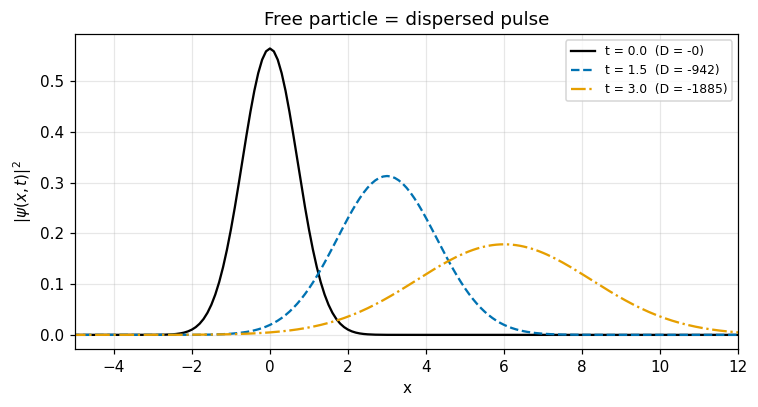

Figure 1. Probability density of a Gaussian packet (k0 = 2, s0 = 1) at t = 0 (solid black), 1.5 (dashed blue) and 3 (dash-dot orange). It drifts right at hbar k0/m = 2 and spreads; the area stays 1. In the optics picture these are the same pulse after three fiber lengths, and any two of the later curves are the two "measurements" GS uses.


,t,D,norm,center,center_exact,width,width_exact
0,0.0,-0.000000,1.0,-0.0,0.0,1.000000,1.000000
1,1.5,-942.477796,1.0,3.0,3.0,1.802776,1.802776
2,3.0,-1884.955592,1.0,6.0,6.0,3.162278,3.162278


In [3]:
x = (np.arange(2048) - 1024) * 0.1
p0 = q.gaussian_packet(x, 1.0, k0=2.0)
times = [0.0, 1.5, 3.0]
rows = []
fig, ax = plt.subplots(figsize=(7, 3.8))
for tt, c, ls in zip(times, [OI['black'], OI['blue'], OI['orange']], ['-', '--', '-.']):
    pt = q.free_evolve(p0, tt, dx=0.1)
    nrm, mean, width = q.density_moments(x, pt, 0.1)
    rows.append(dict(t=tt, D=float(q.D_from_time(tt, dx=0.1)), norm=nrm, center=mean, center_exact=2.0*tt,
                     width=width, width_exact=float(q.packet_width(1.0, tt))))
    ax.plot(x, np.abs(pt)**2, ls, color=c, label=f't = {tt}  (D = {q.D_from_time(tt, dx=0.1):.0f})')
ax.set(xlim=(-5, 12), xlabel='x', ylabel='$|\\psi(x,t)|^2$', title='Free particle = dispersed pulse'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 1. Probability density of a Gaussian packet (k0 = 2, s0 = 1) at t = 0 (solid black), 1.5 (dashed blue) and '
      '3 (dash-dot orange). It drifts right at hbar k0/m = 2 and spreads; the area stays 1. In the optics picture these are '
      'the same pulse after three fiber lengths, and any two of the later curves are the two "measurements" GS uses.')
pd.DataFrame(rows).round(12)

## 3. Figure 2: the Pauli problem, solved by dispersion-assisted GS

Unknown state: a smooth **phase-only** wavefunction $\psi_0(x)=e^{i\phi(x)}$ (`gs_core`'s standard test signal, $N=512$). It is constant in magnitude, like a phase-encoded optical signal, which gives GS the prior $|\psi_0|=1$. We "measure" only $|\psi(x,t_1)|^2$ and $|\psi(x,t_2)|^2$ at $t_1=800$, $t_2=920$ ($D_1\approx-5027$, $D_2\approx-5781$, the repo's working regime) and run 150 GS iterations.

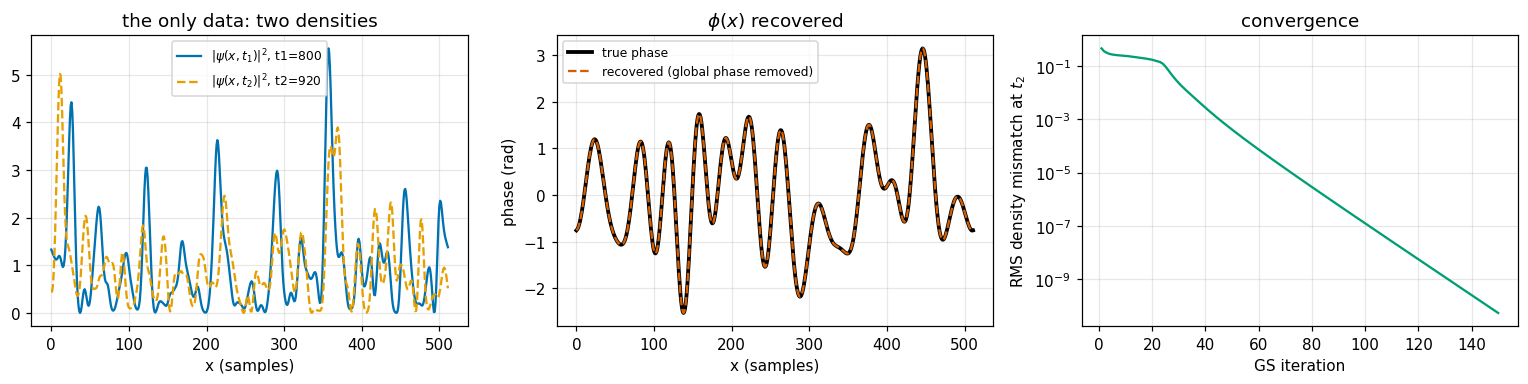

Figure 2. Left: the two measured probability densities (solid blue at t1, dashed orange at t2), the only input. Middle: true phase (thick black) and recovered phase (dashed red) after removing the global phase; they overlap. Right: density mismatch per GS iteration on a log scale, falling steadily to round-off.
phase RMS error = 1.20e-10 rad; mismatch 4.64e-01 -> 5.31e-11


In [4]:
t1, t2 = 800.0, 920.0
psi0 = q.phase_only_state(512)
I1, I2 = q.pauli_measurements(psi0, t1, t2)
rec, err = q.pauli_retrieve(I1, I2, t1, t2, n_iter=150)
from dgs.phase_retrieval_ambiguities import global_phase_align
aligned = global_phase_align(psi0, rec)
n = np.arange(512)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(n, I1, '-', color=OI['blue'], label=f'$|\\psi(x,t_1)|^2$, t1={t1:.0f}')
ax[0].plot(n, I2, '--', color=OI['orange'], label=f'$|\\psi(x,t_2)|^2$, t2={t2:.0f}')
ax[0].set(xlabel='x (samples)', title='the only data: two densities'); ax[0].legend(fontsize=8)
ax[1].plot(n, np.unwrap(np.angle(psi0)), '-', color=OI['black'], lw=2.5, label='true phase')
ax[1].plot(n, np.unwrap(np.angle(aligned)), '--', color=OI['red'], label='recovered (global phase removed)')
ax[1].set(xlabel='x (samples)', ylabel='phase (rad)', title='$\\phi(x)$ recovered'); ax[1].legend(fontsize=8)
ax[2].semilogy(np.arange(1, len(err)+1), err, '-', color=OI['green'])
ax[2].set(xlabel='GS iteration', ylabel='RMS density mismatch at $t_2$', title='convergence')
plt.tight_layout(); plt.show()
print('Figure 2. Left: the two measured probability densities (solid blue at t1, dashed orange at t2), the only input. '
      'Middle: true phase (thick black) and recovered phase (dashed red) after removing the global phase; they overlap. '
      'Right: density mismatch per GS iteration on a log scale, falling steadily to round-off.')
print(f'phase RMS error = {q.phase_rms_error(psi0, rec):.2e} rad; mismatch {err[0]:.2e} -> {err[-1]:.2e}')

## 4. What can't be recovered, and why that's physics

* **Global phase.** $e^{i\alpha}\psi$ gives identical densities at every time. In QM it's the same state, so GS can only return $\psi$ up to $e^{i\alpha}$ (Fig. 2 removed it before comparing).
* **Time-reversed twin.** Complex conjugation reverses time: $|\overline{\psi}(x,t)|^2=|\psi(x,-t)|^2$. So $\overline{\psi_0}$ reproduces the measurements taken at $-t_1,-t_2$, but not those at $+t_1,+t_2$. Measuring on one side of $t=0$, with $t_1\ne t_2$, breaks the twin ambiguity. In fiber terms: two dispersions of the same sign.

In [5]:
cands = {'true psi0': psi0, 'e^{0.7i} psi0 (global phase)': np.exp(0.7j)*psi0,
         'conj(psi0) (twin)': np.conj(psi0), 'recovered (GS)': rec}
rows = [dict(candidate=k, mismatch_at_plus_t=q.measurement_mismatch(v, I1, I2, t1, t2),
             mismatch_at_minus_t=q.measurement_mismatch(v, I1, I2, -t1, -t2),
             distance_to_truth_mod_global_phase=q.relative_error(psi0, v)) for k, v in cands.items()]
print(f'time-reversal identity: max | |conj psi(t)|^2 - |psi(-t)|^2 | = {q.time_reversal_check(psi0, t1):.1e}')
pd.DataFrame(rows)

time-reversal identity: max | |conj psi(t)|^2 - |psi(-t)|^2 | = 2.7e-15


,candidate,mismatch_at_plus_t,mismatch_at_minus_t,distance_to_truth_mod_global_phase
0,true psi0,0.000000e+00,1.753186e+00,0.000000e+00
1,e^{0.7i} psi0 (global phase),8.907567e-16,1.753186e+00,1.490116e-08
2,conj(psi0) (twin),1.753186e+00,7.969768e-16,1.360012e+00
3,recovered (GS),8.428279e-11,1.753186e+00,0.000000e+00


## 5. Figure 3: the qubit analog (bases are dispersions)

$|\psi\rangle=\cos\frac\theta2|0\rangle+e^{i\phi}\sin\frac\theta2|1\rangle$ with $\theta=\pi/2$. Each basis is a **known unitary followed by a Z measurement**, which is the analog of "disperse, then detect intensity":

| measurement | unitary before Z | $P(0)$ | phase information |
|---|---|---|---|
| Z | $\mathbb 1$ | $\tfrac12$ | none (the intensity is blind to phase) |
| X | $H$ | $\tfrac12(1+\cos\phi)$ | $\pm\phi$ (twin ambiguity) |
| Y | $HS^\dagger$ | $\tfrac12(1+\sin\phi)$ | with X: $\phi=\operatorname{atan2}(\langle Y\rangle,\langle X\rangle)$ |

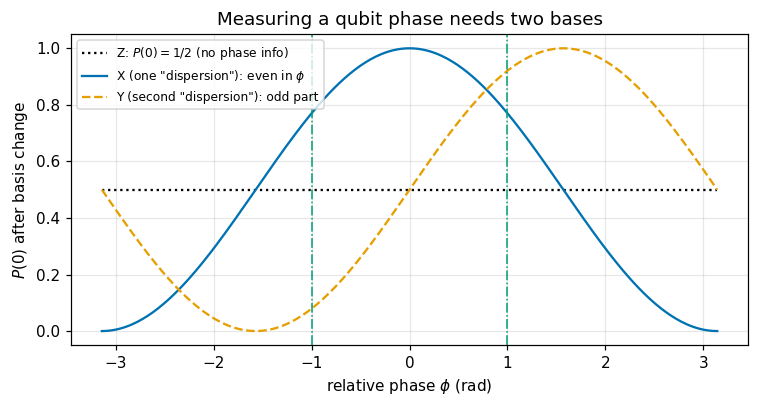

Figure 3. Probability of outcome 0 against the hidden phase phi. Z (dotted black) is flat: no information. X (solid blue) is symmetric, so phi = +1 and -1 (dash-dot green lines) give the same reading: the twin ambiguity. Y (dashed orange) differs between them, so X and Y together fix phi, as D1 and D2 do for the wavefunction.


,phi_true,P0_X,P0_Y,from_X_only,from_X_and_Y,qiskit_X_Y
0,-2.5,0.099428,0.200764,[ 2.5 -2.5],-2.5,[-0.801144 -0.598472]
1,-1.0,0.770151,0.079265,[ 1. -1.],-1.0,[ 0.540302 -0.841471]
2,0.3,0.977668,0.647760,[ 0.3 -0.3],0.3,[0.955336 0.29552 ]
3,2.0,0.291927,0.954649,[ 2. -2.],2.0,[-0.416147 0.909297]


In [6]:
phis = np.linspace(-np.pi, np.pi, 361)
P = {b: np.array([q.basis_probability0(q.qubit_state(np.pi/2, p), b) for p in phis]) for b in 'ZXY'}
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(phis, P['Z'], ':', color=OI['black'], label='Z: $P(0)=1/2$ (no phase info)')
ax.plot(phis, P['X'], '-', color=OI['blue'], label='X (one "dispersion"): even in $\\phi$')
ax.plot(phis, P['Y'], '--', color=OI['orange'], label='Y (second "dispersion"): odd part')
ax.axvline(1.0, color=OI['green'], ls='-.', lw=1); ax.axvline(-1.0, color=OI['green'], ls='-.', lw=1)
ax.set(xlabel='relative phase $\\phi$ (rad)', ylabel='$P(0)$ after basis change', title='Measuring a qubit phase needs two bases'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 3. Probability of outcome 0 against the hidden phase phi. Z (dotted black) is flat: no information. X (solid blue) '
      'is symmetric, so phi = +1 and -1 (dash-dot green lines) give the same reading: the twin ambiguity. Y (dashed orange) '
      'differs between them, so X and Y together fix phi, as D1 and D2 do for the wavefunction.')
rows = []
for phi in (-2.5, -1.0, 0.3, 2.0):
    s = q.qubit_state(np.pi/2, phi)
    px, py = q.basis_probability0(s, 'X'), q.basis_probability0(s, 'Y')
    qk = q.qiskit_expectations(np.pi/2, phi)
    rows.append(dict(phi_true=phi, P0_X=px, P0_Y=py, from_X_only=str(np.round(q.phase_from_x_only(px), 4)),
                     from_X_and_Y=q.phase_from_xy(px, py),
                     qiskit_X_Y=('not installed' if qk is None else str(np.round(qk[:2], 6)))))
pd.DataFrame(rows)

## 6. Figure 4: the computer-engineering view

One GS iteration is a fixed **dataflow**: `FFT → ×H(D₁) → IFFT → replace |·| with √I₁ → FFT → ×H*(D₁) → IFFT → (|ψ|=1) → same for D₂`. It's $O(N\log N)$ and streams well, so it maps onto GPUs (`dgs/gs_cuda.py`, CuPy) or FPGA FFT cores. The detector in front is an **ADC**, and quantizing $I_1,I_2$ to $b$ bits limits how well the phase comes back. Below: an operation-count *model*, one *measured* timing on this CPU, and an ADC-bit sweep.

measured on this machine (NumPy, N=1024, best of 3): 808 us per GS iteration -> ~0.32 GFLOP/s by the model count (machine- and load-dependent).


,N,flops_model
0,256,55296
1,1024,262144
2,4096,1212416
3,16384,5505024


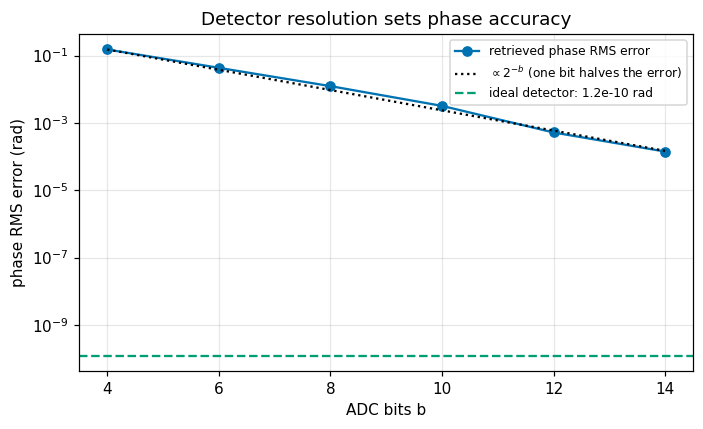

Figure 4. Phase RMS error of the recovered wavefunction against ADC resolution (blue circles, solid), with a 2^-b reference (dotted black) and the unquantized limit (dashed green). Each extra bit roughly halves the error, so about 8 bits gives ~0.01 rad.


,bits,phase_rms_rad,relative_error
0,4,1.511318e-01,0.150683
1,6,4.310968e-02,0.043100
2,8,1.234192e-02,0.012342
3,10,3.198331e-03,0.003198
4,12,5.191013e-04,0.000519
5,14,1.406078e-04,0.000141
6,ideal,1.203129e-10,0.000000


In [7]:
rows = [dict(N=n, flops_model=q.gs_flops_per_iteration(n)) for n in (256, 1024, 4096, 16384)]
df_f = pd.DataFrame(rows)
t_it = q.time_gs_iterations(1024, n_iter=50)
print(f'measured on this machine (NumPy, N=1024, best of 3): {t_it*1e6:.0f} us per GS iteration '
      f'-> ~{q.gs_flops_per_iteration(1024)/t_it/1e9:.2f} GFLOP/s by the model count (machine- and load-dependent).')
display(df_f)
sweep = q.adc_bit_sweep(bits_list=(4, 6, 8, 10, 12, 14, None), n=512, n_iter=150)
bits = np.array([b for b, _, _ in sweep if b is not None]); e = np.array([r for b, r, _ in sweep if b is not None])
ideal = [r for b, r, _ in sweep if b is None][0]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.semilogy(bits, e, 'o-', color=OI['blue'], label='retrieved phase RMS error')
ax.semilogy(bits, e[0]*2.0**-(bits-bits[0]), ':', color=OI['black'], label='$\\propto 2^{-b}$ (one bit halves the error)')
ax.axhline(ideal, color=OI['green'], ls='--', label=f'ideal detector: {ideal:.1e} rad')
ax.set(xlabel='ADC bits b', ylabel='phase RMS error (rad)', title='Detector resolution sets phase accuracy'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 4. Phase RMS error of the recovered wavefunction against ADC resolution (blue circles, solid), with a 2^-b '
      'reference (dotted black) and the unquantized limit (dashed green). Each extra bit roughly halves the error, so '
      'about 8 bits gives ~0.01 rad.')
pd.DataFrame([dict(bits=b if b is not None else 'ideal', phase_rms_rad=r, relative_error=re_) for b, r, re_ in sweep])

## 7. Mastery map, and "what is it worth?"

| Knight Ch. 40 | this repo | computer-engineering skill it trains |
|---|---|---|
| 40.1–40.2 Schrödinger equation, solving it | `free_evolve`, `gs_core.disperse` | FFT-based linear-system simulation, transfer functions |
| 40.3–40.5 box, correspondence | `stationary_states`, `diffraction_dispersion` (far field = DFT) | eigen-solvers, stationary phase ↔ spectrum analysis |
| 40.6–40.7 finite wells, shapes | `finite_square_well`, `schrodinger_separation_industry` | sparse matrices, residual-based verification |
| 40.8 harmonic oscillator | qubit truncation (§5), trapped-ion / transmon models | quantum-control signal chains (DAC/ADC, basis rotations) |
| 40.10 tunneling | `tunneling`, gate-oxide / flash models | device physics behind CMOS and NAND |
| measurement $\lvert\psi\rvert^2$ | **TD-GS phase retrieval** (this notebook) | iterative algorithms, ADC/quantization budgets, GPU/FPGA dataflow |

**"$?"**: I read this as "what is it worth?". The honest answer is the skill set, not a salary figure (I don't have reliable numbers). The same three skills show up in quantum-hardware control, coherent optical DSP, and GPU simulation work: (1) modeling a linear propagator in the Fourier domain, (2) recovering information a detector throws away from known transformations plus intensity measurements, and (3) budgeting bits, FLOPs and latency for that pipeline. This notebook exercises all three on one problem. The repo's bench capstone (real I₁/I₂ measurements) would turn it from a simulation into evidence.

**References** (from memory; verify before citing)
[1] W. Pauli, "Die allgemeinen Prinzipien der Wellenmechanik," in *Handbuch der Physik*, vol. 24, H. Geiger and K. Scheel, Eds. Berlin, Germany: Springer, 1933.
[2] R. W. Gerchberg and W. O. Saxton, "A practical algorithm for the determination of phase from image and diffraction plane pictures," *Optik*, vol. 35, pp. 237–246, 1972.
[3] D. R. Solli, S. Gupta, and B. Jalali, "Optical phase recovery in the dispersive Fourier transform," *Appl. Phys. Lett.*, vol. 95, Art. no. 231108, 2009.
[4] J. R. Fienup, "Phase retrieval algorithms: a comparison," *Appl. Opt.*, vol. 21, no. 15, pp. 2758–2769, 1982.
[5] M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, 10th anniv. ed. Cambridge, U.K.: Cambridge Univ. Press, 2010.
[6] R. D. Knight, *Physics for Scientists and Engineers with Modern Physics*, 5th ed. Pearson, ch. 40.

**Limitations.**
- The retrieval demo uses a phase-only state, the same constant-envelope prior `gs_core` relies on. A general wavefunction with an unknown amplitude needs `unit_amplitude=False` and more measurement diversity.
- The FLOP count is a model.
- The timing is one measurement on this machine.
- No noise other than ADC quantization is included.